# 01. LeRobot 데이터셋 구조 파악

**목표**: 파이프라인을 짜기 전에 데이터가 *어떻게 생겼는지* 먼저 안다.
- 어떤 파일이 있고, 한 행(row)은 무엇을 뜻하는가?
- 에피소드는 어떻게 구분되는가?
- 품질 검사 4가지(길이 / 결측 / 타임스탬프 / 범위)를 하려면 어떤 컬럼을 봐야 하는가?

대상: `lerobot/aloha_sim_insertion_human` (양팔 로봇 ALOHA 시뮬레이션, 사람이 원격조작으로 막대 꽂기 시연)

## 1. 다운로드 (표 데이터만, 영상 제외)

In [3]:
from pathlib import Path
from huggingface_hub import snapshot_download

REPO_ID = "lerobot/aloha_sim_insertion_human"
LOCAL = Path("../data/hf/aloha_sim_insertion_human")

# allow_patterns: data/(프레임 데이터), meta/(메타데이터)만 받고 videos/(약 88MB)는 건너뜀
snapshot_download(REPO_ID, repo_type="dataset",
                  allow_patterns=["data/*", "meta/*"], local_dir=LOCAL)

for f in sorted(LOCAL.rglob("*")):
    if f.is_file() and ".cache" not in f.parts:
        print(f"{f.stat().st_size/1e3:8.1f} KB  {f.relative_to(LOCAL)}")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

   855.8 KB  data/chunk-000/file-000.parquet
   847.6 KB  data/chunk-000/file-001.parquet
   855.6 KB  data/chunk-000/file-002.parquet
   293.3 KB  data/chunk-000/file-003.parquet
    88.3 KB  meta/episodes/chunk-000/file-000.parquet
     2.7 KB  meta/info.json
     7.0 KB  meta/stats.json
     2.2 KB  meta/tasks.parquet


## 2. `meta/info.json` — 데이터셋의 '설명서'
여기에 fps, 컬럼(features) 이름·타입·shape가 다 정의돼 있다.
→ 파이프라인은 컬럼 이름을 하드코딩하지 않고 **이 파일을 읽어서** 동작하게 만들 수 있다 (다른 데이터셋에도 재사용).

In [4]:
import json
info = json.loads((LOCAL / "meta/info.json").read_text())
print({k: info[k] for k in ["codebase_version", "robot_type", "total_episodes", "total_frames", "fps"]})
for name, f in info["features"].items():
    print(f"{name:28s} {f['dtype']:8s} shape={f['shape']}")

{'codebase_version': 'v3.0', 'robot_type': 'aloha', 'total_episodes': 50, 'total_frames': 25000, 'fps': 50}
observation.images.top       video    shape=[480, 640, 3]
observation.state            float32  shape=[14]
action                       float32  shape=[14]
episode_index                int64    shape=[1]
frame_index                  int64    shape=[1]
timestamp                    float32  shape=[1]
next.done                    bool     shape=[1]
index                        int64    shape=[1]
task_index                   int64    shape=[1]


In [5]:
JOINTS = info["features"]["observation.state"]["names"]["motors"]
print(len(JOINTS), JOINTS)

14 ['left_waist', 'left_shoulder', 'left_elbow', 'left_forearm_roll', 'left_wrist_angle', 'left_wrist_rotate', 'left_gripper', 'right_waist', 'right_shoulder', 'right_elbow', 'right_forearm_roll', 'right_wrist_angle', 'right_wrist_rotate', 'right_gripper']


## 3. 프레임 데이터 (`data/*.parquet`)
**1행 = 1프레임 (1/50초 순간)의 로봇 상태**.
- `observation.state`: 그 순간 관절 14개의 실제 위치 (센서값)
- `action`: 그 순간 로봇에게 내린 명령 (원격조작자가 움직인 값) → 모델이 배워야 하는 정답
- `episode_index`: 몇 번째 시연인지, `frame_index`: 시연 안에서 몇 번째 프레임인지

In [6]:
import pandas as pd
files = sorted((LOCAL / "data").rglob("*.parquet"))
df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
print(len(files), "files →", df.shape)
df.head()

4 files → (25000, 8)


,observation.state,action,episode_index,frame_index,timestamp,next.done,index,task_index
0,"[0.0, -0.96, 1.16, 0.0, -0.3, 0.0, 0.0, 0.0, -...","[0.009203885, -0.9341943, 1.1734953, -0.004601...",0,0,0.00,False,0,0
1,"[0.0007582012, -0.9566894, 1.1651634, -0.00142...","[0.009203885, -0.9341943, 1.1734953, -0.003067...",0,1,0.02,False,1,0
2,"[0.0018032654, -0.9522623, 1.1714675, -0.00530...","[0.0076699043, -0.93266034, 1.1734953, -0.0046...",0,2,0.04,False,2,0
3,"[0.0026358203, -0.9482949, 1.1752888, -0.00741...","[0.009203885, -0.93266034, 1.1750293, -0.00460...",0,3,0.06,False,3,0
4,"[0.0034279125, -0.9450332, 1.177441, -0.008036...","[0.009203885, -0.93266034, 1.1750293, -0.00460...",0,4,0.08,False,4,0


⚠️ `observation.state`, `action`은 **한 칸에 숫자 14개짜리 배열**이 들어 있다 (dtype=object).
SQL로 조회하거나 컬럼별 범위 검사를 하려면 관절별 컬럼 14개로 펼쳐야 한다 → **curated 단계의 변환 작업**이 된다.

In [7]:
import numpy as np
state = pd.DataFrame(np.stack(df["observation.state"].values), columns=[f"state_{j}" for j in JOINTS])
state.iloc[:3, :5]

,state_left_waist,state_left_shoulder,state_left_elbow,state_left_forearm_roll,state_left_wrist_angle
0,0.000000,-0.960000,1.160000,0.000000,-0.300000
1,0.000758,-0.956689,1.165163,-0.001430,-0.303506
2,0.001803,-0.952262,1.171468,-0.005306,-0.304356


## 4. 에피소드 메타 (`meta/episodes/*.parquet`)
v3.0 포맷은 **에피소드 1개 = 파일 1개가 아니다**. 여러 에피소드가 한 파일에 묶여 있고,
'몇 번 에피소드는 몇 번 파일의 몇~몇 행'인지는 이 메타 파일이 알려준다. → PostgreSQL `episodes` 테이블의 원재료.

In [8]:
ep = pd.concat([pd.read_parquet(f) for f in sorted((LOCAL / "meta/episodes").rglob("*.parquet"))])
print(ep.shape)
ep[["episode_index", "data/file_index", "dataset_from_index", "dataset_to_index", "length", "tasks"]].head()

(50, 58)


,episode_index,data/file_index,dataset_from_index,dataset_to_index,length,tasks
0,0,0,0,500,500,[Insert the peg into the socket.]
1,1,0,500,1000,500,[Insert the peg into the socket.]
2,2,0,1000,1500,500,[Insert the peg into the socket.]
3,3,0,1500,2000,500,[Insert the peg into the socket.]
4,4,0,2000,2500,500,[Insert the peg into the socket.]


## 5. 품질 검사 4가지 — 원본 데이터에 먼저 돌려보기

In [9]:
FPS = info["fps"]

def quality_report(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for ep_idx, g in df.groupby("episode_index"):
        st = np.stack(g["observation.state"].values)
        dt = g["timestamp"].diff().dropna()
        rows.append({
            "episode_index": ep_idx,
            "n_frames": len(g),
            "n_null": int(g.isna().sum().sum() + np.isnan(st).sum()),        # 결측
            "n_gap": int((dt > 1.5 / FPS).sum()),                             # 프레임 누락 (간격이 1.5배 이상 벌어진 곳)
            "max_abs_joint": float(np.nanmax(np.abs(st))),                    # 범위 확인용
        })
    return pd.DataFrame(rows)

report = quality_report(df)
report.describe().T[["min", "max", "mean"]]

,min,max,mean
episode_index,0.00,49.000000,24.500000
n_frames,500.00,500.000000,500.000000
n_null,0.00,0.000000,0.000000
n_gap,0.00,0.000000,0.000000
max_abs_joint,1.16,1.215762,1.177707


**관찰**: 모든 에피소드가 500프레임, 결측 0, 누락 0.
공개 데이터셋은 이미 정제된 상태라 검사에 걸리는 게 없다.
→ 실제 현장(원격조작 수집) 데이터는 이렇지 않을 것. **결함을 일부러 넣어서 검사 로직이 제대로 잡는지 검증**한다.

## 6. 정상 범위 기준 정하기
관절별 정상 범위 = 전체 데이터의 min/max에 약간 여유(margin)를 둔 값.
(실제 현장이라면 로봇 스펙의 관절 한계값을 쓰는 게 정석)

In [10]:
lo, hi = state.min(), state.max()
margin = (hi - lo) * 0.1
bounds = pd.DataFrame({"min": lo - margin, "max": hi + margin})
bounds.index = JOINTS
bounds.round(3)

,min,max
left_waist,-0.346,0.377
left_shoulder,-1.064,0.179
left_elbow,0.217,1.293
left_forearm_roll,-0.318,0.330
left_wrist_angle,-0.642,1.149
left_wrist_rotate,-0.509,0.527
left_gripper,-0.109,1.200
right_waist,-0.557,0.400
right_shoulder,-1.110,0.327
right_elbow,-0.018,1.328


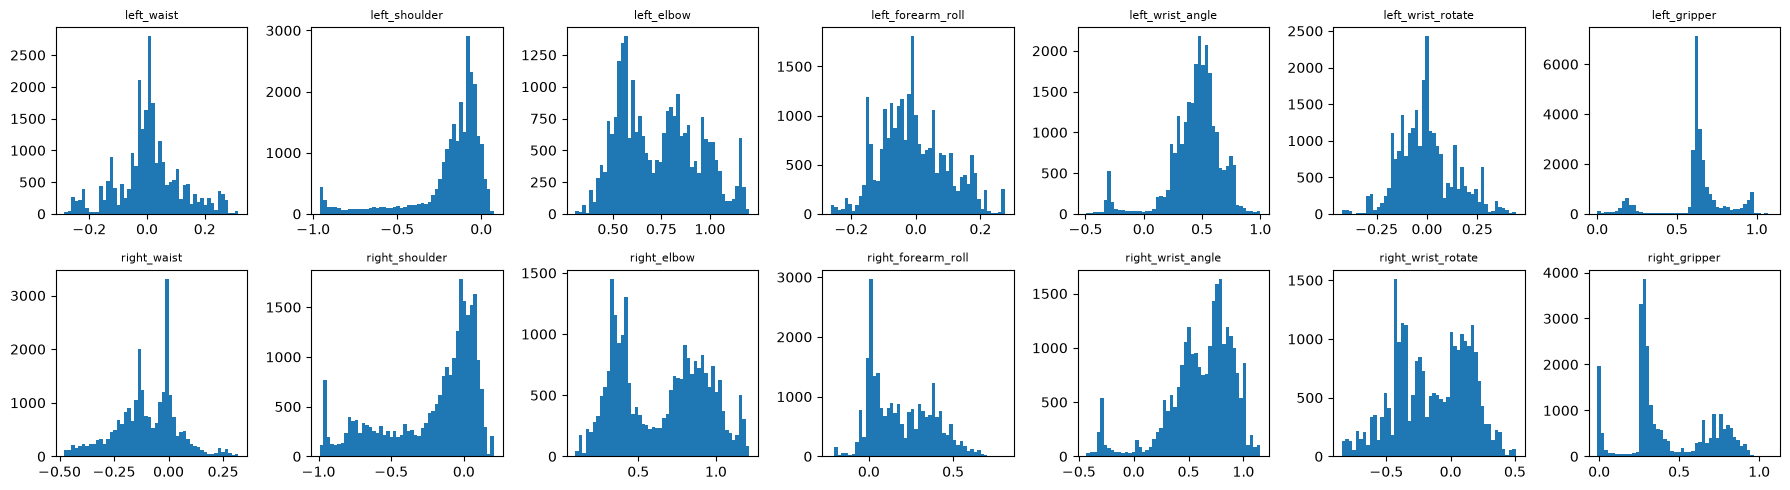

In [11]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 7, figsize=(18, 5), sharey=False)
for ax, col, j in zip(axes.flat, state.columns, JOINTS):
    ax.hist(state[col], bins=50); ax.set_title(j, fontsize=8)
plt.tight_layout(); plt.show()

## 7. 결함 주입 → 검사가 잡아내는지 확인

In [12]:
rng = np.random.default_rng(42)
bad = df.copy()

# (1) 에피소드 3: 중간 프레임 20개 삭제 → 타임스탬프 끊김 + 길이 짧아짐
drop = bad[(bad.episode_index == 3) & bad.frame_index.between(200, 219)].index
bad = bad.drop(drop)

# (2) 에피소드 7: 뒤쪽 400프레임 잘림 → 비정상적으로 짧은 에피소드
bad = bad[~((bad.episode_index == 7) & (bad.frame_index >= 100))]

# (3) 에피소드 12: 관절값 5개를 NaN으로 (센서 값 유실)
idx = bad[bad.episode_index == 12].sample(5, random_state=1).index
bad.loc[idx, "observation.state"] = bad.loc[idx, "observation.state"].apply(lambda a: np.where(np.arange(14) == 2, np.nan, a))

# (4) 에피소드 20: 한 프레임 left_elbow 값 튐 (센서 노이즈)
i = bad[(bad.episode_index == 20) & (bad.frame_index == 250)].index[0]
a = bad.at[i, "observation.state"].copy(); a[2] = 9.9; bad.at[i, "observation.state"] = a

r = quality_report(bad)
r["out_of_range"] = [
    int(((np.stack(g["observation.state"].values) < bounds["min"].values) |
         (np.stack(g["observation.state"].values) > bounds["max"].values)).sum())
    for _, g in bad.groupby("episode_index")
]
r[(r.n_frames != 500) | (r.n_null > 0) | (r.n_gap > 0) | (r.out_of_range > 0)]

,episode_index,n_frames,n_null,n_gap,max_abs_joint,out_of_range
3,3,480,0,1,1.166678,0
7,7,100,0,0,1.194088,0
12,12,500,5,0,1.183271,0
20,20,500,0,0,9.900000,1


**결과**: 넣은 결함 4개가 각각 다른 검사 항목에 걸린다.

| 에피소드 | 넣은 결함 | 잡힌 항목 |
|---|---|---|
| 3 | 중간 20프레임 삭제 | n_frames, n_gap |
| 7 | 뒤쪽 잘림 | n_frames |
| 12 | 관절값 결측 | n_null |
| 20 | 값 튐 | out_of_range |

## 정리 → 파이프라인 설계로
- **raw 버킷**: `data/`, `meta/` 원본 그대로 (나중에 규칙이 바뀌어도 원본에서 다시 처리할 수 있게)
- **품질 테이블**: 위 `quality_report` 결과를 에피소드 단위로 PostgreSQL에 적재
- **curated 버킷**: 배열을 관절별 컬럼으로 펼친 Parquet, 품질 통과한 에피소드만
- **episodes 테이블**: 에피소드 메타 (길이, 파일 위치, 품질 통과 여부)
- 컬럼·fps는 `info.json`에서 읽기 → 다른 LeRobot 데이터셋에도 재사용 가능